# 04_analysis

**Input:** `rides_features.parquet` (built by notebook 03), plus `rides_combined_raw.parquet` for one robustness check at the end

**Output:** printed tables and one rough plot, no files saved

**Why it exists:** compares casual and member riders on group size, ride length, bike type, day of week, season, hour of day and starting station, then re-runs the headline numbers with the sub-minute rides removed vs kept to test whether removing them changed the conclusions.


In [1]:
import pandas as pd
rides = pd.read_parquet("../data/clean/rides_features.parquet")

# 1. Size of each group
print(rides["member_casual"].value_counts())
print(rides["member_casual"].value_counts(normalize=True).round(3))

# 2. Ride length in minutes: median and mean
print(rides.groupby("member_casual", observed=True)["ride_min"].agg(["median", "mean", "count"]).round(1))

# 3. Ride length by bike type
print(rides.groupby(["member_casual", "rideable_type"], observed=True)["ride_min"].agg(["median", "count"]).round(1))

# 4. Day of week: share of EACH group's rides
print(pd.crosstab(rides["day_of_week"], rides["member_casual"], normalize="columns").round(3))

# 5. Season: share of EACH group's rides
print(pd.crosstab(rides["season"], rides["member_casual"], normalize="columns").round(3).reindex(["Winter", "Spring", "Summer", "Fall"]))

member_casual
member    3896850
casual    2110304
Name: count, dtype: int64
member_casual
member    0.649
casual    0.351
Name: proportion, dtype: float64
               median  mean    count
member_casual                       
casual           11.1  18.2  2110304
member            8.7  12.2  3896850
                             median    count
member_casual rideable_type                 
casual        classic_bike     15.6   544453
              electric_bike    10.1  1565851
member        classic_bike      9.2  1234604
              electric_bike     8.5  2662246
member_casual  casual  member
day_of_week                  
Monday          0.115   0.140
Tuesday         0.114   0.161
Wednesday       0.117   0.162
Thursday        0.125   0.158
Friday          0.157   0.147
Saturday        0.212   0.128
Sunday          0.160   0.105
member_casual  casual  member
season                       
Winter          0.043   0.097
Spring          0.212   0.239
Summer          0.464   0.374
Fall   

                        median    count
member_casual day_type                 
casual        Weekday     10.3  1325495
              Weekend     12.9   784809
member        Weekday      8.5  2990496
              Weekend      9.4   906354


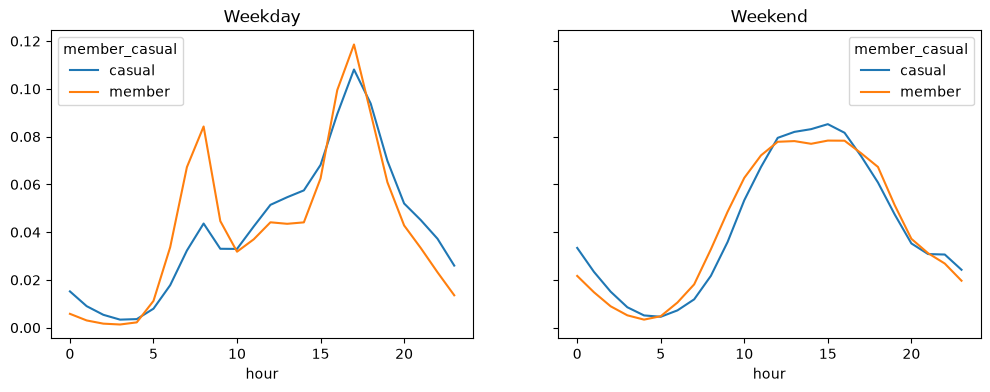

In [2]:
# Does ride length change on weekends, and how do the groups' hour-of-day ride patterns compare (rough exploratory plot, weekday vs weekend)

import matplotlib.pyplot as plt

# A. Does ride length change on weekends?
print(rides.groupby(["member_casual", "day_type"], observed=True)["ride_min"]
      .agg(["median", "count"]).round(1))

# B. Hour of day, share of each group's rides (rough exploratory plot)
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, dt in zip(ax, ["Weekday", "Weekend"]):
    sub = rides[rides["day_type"] == dt]
    pd.crosstab(sub["hour"], sub["member_casual"], normalize="columns").plot(ax=a, title=dt)
plt.show()

In [3]:
# Which start stations do casual riders use most, and where is the casual share of all rides highest

st = rides.dropna(subset=["start_station_name"])
print("share of rides with a start station:", round(len(st) / len(rides), 3))

tab = (st.groupby(["start_station_name", "member_casual"], observed=True)
         .size().unstack(fill_value=0))
tab["total"] = tab["casual"] + tab["member"]
tab["casual_share"] = (tab["casual"] / tab["total"]).round(3)

print("Top 15 by casual rides:")
print(tab.sort_values("casual", ascending=False).head(15))
print("Highest casual share, stations with 5,000+ rides:")
print(tab[tab["total"] >= 5000].sort_values("casual_share", ascending=False).head(15))

share of rides with a start station: 0.8
Top 15 by casual rides:
member_casual                       casual  member  total  casual_share
start_station_name                                                     
Navy Pier                            49557   15864  65421         0.758
DuSable Lake Shore Dr & Monroe St    28566    7813  36379         0.785
Michigan Ave & Oak St                20660   13466  34126         0.605
DuSable Lake Shore Dr & North Blvd   16931   14047  30978         0.547
Millennium Park                      16835    8435  25270         0.666
Shedd Aquarium                       16055    3617  19672         0.816
Theater on the Lake                  14756   11267  26023         0.567
Dusable Harbor                       13629    5348  18977         0.718
Field Museum                         10021    2348  12369         0.810
Adler Planetarium                     9993    3845  13838         0.722
Montrose Harbor                       9942    7819  17761         0.560

In [4]:
# Define the commute window (weekdays, hours 7-8 and 16-17), measure each group's baseline share in it, and rank stations by how commute-like their casual rides are

st = rides.dropna(subset=["start_station_name"]).copy()
st["commute_window"] = (st["day_type"] == "Weekday") & st["hour"].isin([7, 8, 16, 17])

cas = st[st["member_casual"] == "casual"]
print("baseline commute-window share, casual:", round(cas["commute_window"].mean(), 3))
print("baseline commute-window share, member:", round(st[st["member_casual"] == "member"]["commute_window"].mean(), 3))
print("top 15 stations = share of docked casual rides:",
      round(cas["start_station_name"].value_counts().head(15).sum() / len(cas), 3))

by = cas.groupby("start_station_name", observed=True).agg(
    casual_rides=("ride_id", "size"),
    commute_share=("commute_window", "mean"),
    median_min=("ride_min", "median"))
tot = st.groupby("start_station_name", observed=True).size()
by["casual_share"] = (by["casual_rides"] / tot.reindex(by.index)).round(3)

big = by[by["casual_rides"] >= 3000]
print("Most commute-like casual stations:")
print(big.sort_values("commute_share", ascending=False).head(15).round(2))
print("Least commute-like casual stations:")
print(big.sort_values("commute_share").head(10).round(2))

baseline commute-window share, casual: 0.176
baseline commute-window share, member: 0.291
top 15 stations = share of docked casual rides: 0.145
Most commute-like casual stations:
                                     casual_rides  commute_share  median_min  \
start_station_name                                                             
Clinton St & Washington Blvd 2               4079           0.38       10.32   
Elston Ave & Cortland St                     3395           0.36        9.71   
Canal St & Madison St                        6354           0.36        9.93   
Wells St & Randolph St                       3611           0.33        9.81   
Clinton St & Lake St                         3884           0.33        8.43   
Canal St & Adams St                          3824           0.32       10.40   
Clinton St & Jackson Blvd                    5144           0.31       10.42   
Ravenswood Ave & Lawrence Ave                4777           0.31        8.61   
Kingsbury St & Kinzie

In [6]:
# Re-run the headline numbers with sub-minute rides removed and compare them with kept, to see whether the conclusions change

raw = pd.read_parquet("../data/clean/rides_combined_raw.parquet",
                      columns=["ride_id", "started_at", "ended_at", "member_casual"])
raw = raw.drop_duplicates(subset="ride_id")
raw["dur_sec"] = (raw["ended_at"] - raw["started_at"]).dt.total_seconds()
raw = raw[(raw["started_at"] >= "2025-10-01") & (raw["dur_sec"] > 0) & (raw["dur_sec"] <= 86400)]
raw["ride_min"] = raw["dur_sec"] / 60
raw["is_weekend"] = raw["started_at"].dt.day_of_week >= 5
raw["is_summer"] = raw["started_at"].dt.month.isin([6, 7, 8])

rides["is_weekend"] = rides["day_type"] == "Weekend"
rides["is_summer"] = rides["season"] == "Summer"

def headline(df):
    g = df.groupby("member_casual", observed=True)
    return pd.DataFrame({"rides": g.size(), "median_min": g["ride_min"].median(),
                         "weekend_share": g["is_weekend"].mean(),
                         "summer_share": g["is_summer"].mean()}).round(3)

print("Sub-minute rides REMOVED (clean data):")
print(headline(rides))
print("Sub-minute rides KEPT:")
print(headline(raw))

Sub-minute rides REMOVED (clean data):
                 rides  median_min  weekend_share  summer_share
member_casual                                                  
casual         2110304      11.143          0.372         0.464
member         3896850       8.687          0.233         0.374
Sub-minute rides KEPT:
                 rides  median_min  weekend_share  summer_share
member_casual                                                  
casual         2184772      10.748          0.373         0.463
member         3981574       8.508          0.233         0.373
